In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re

In [68]:
f = open(
    "D:\\Divyam\\WhatsApp Chats\\WhatsApp Chat with F.R.I.E.N.D.S.txt", encoding="utf-8"
)
data = f.read()

In [69]:
pattern = r"\d{1,2}/\d{1,2}/\d{2,4},\s\d{1,2}:\d{2}\s-\s"

In [70]:
messages = re.split(pattern, data)[1:]

dates = re.findall(pattern, data)
dates

['26/05/26, 20:10 - ',
 '25/03/26, 15:34 - ',
 '26/05/26, 20:10 - ',
 '26/05/26, 20:11 - ',
 '26/05/26, 20:11 - ',
 '26/05/26, 20:19 - ',
 '26/05/26, 20:35 - ',
 '26/05/26, 20:36 - ',
 '26/05/26, 20:42 - ',
 '27/05/26, 18:11 - ',
 '27/05/26, 18:12 - ',
 '27/05/26, 18:12 - ',
 '27/05/26, 18:12 - ',
 '27/05/26, 18:13 - ',
 '27/05/26, 18:13 - ',
 '27/05/26, 18:13 - ',
 '27/05/26, 18:13 - ',
 '27/05/26, 18:18 - ',
 '27/05/26, 18:18 - ',
 '27/05/26, 18:18 - ',
 '27/05/26, 18:19 - ',
 '27/05/26, 18:20 - ',
 '27/05/26, 18:20 - ',
 '27/05/26, 18:20 - ',
 '27/05/26, 18:20 - ',
 '27/05/26, 18:20 - ',
 '27/05/26, 19:34 - ',
 '27/05/26, 19:34 - ',
 '27/05/26, 19:49 - ',
 '27/05/26, 19:49 - ',
 '27/05/26, 20:00 - ',
 '27/05/26, 20:03 - ',
 '27/05/26, 20:04 - ',
 '27/05/26, 20:04 - ',
 '28/05/26, 00:39 - ',
 '28/05/26, 09:35 - ',
 '28/05/26, 11:08 - ',
 '28/05/26, 13:40 - ',
 '28/05/26, 14:43 - ',
 '28/05/26, 17:11 - ',
 '28/05/26, 18:57 - ',
 '28/05/26, 19:04 - ',
 '28/05/26, 19:04 - ',
 '29/05/26,

In [71]:
df = pd.DataFrame({"user_message": messages, "message_date": dates})
df["message_date"] = pd.to_datetime(df["message_date"], format="%d/%m/%y, %H:%M - ")
df = df.rename(columns={"message_date": "date"})

df.head()

,user_message,date
0,Messages and calls are end-to-end encrypted. O...,2026-05-26 20:10:00
1,"Mummy created group ""👻👻F.R.I.E.N.D.S👻👻""\n",2026-03-25 15:34:00
2,You joined using this group's invite link\n,2026-05-26 20:10:00
3,✌Divyam✌: Guys call cut karke phir se karo\n,2026-05-26 20:11:00
4,Amrita (Vasu): \n,2026-05-26 20:11:00


In [72]:
df.shape

(2965, 2)

In [73]:
# separate users and messages

users = []
messages = []

for message in df["user_message"]:
    entry = re.split(r"(.*?):\s", message, maxsplit=1)
    if len(entry) > 2:
        users.append(entry[1])
        messages.append(entry[2])
    else:
        users.append("group_notification")
        messages.append(entry[0])

df["user"] = users
df["message"] = messages
df = df.drop(columns=["user_message"])

df.head()

,date,user,message
0,2026-05-26 20:10:00,group_notification,Messages and calls are end-to-end encrypted. O...
1,2026-03-25 15:34:00,group_notification,"Mummy created group ""👻👻F.R.I.E.N.D.S👻👻""\n"
2,2026-05-26 20:10:00,group_notification,You joined using this group's invite link\n
3,2026-05-26 20:11:00,✌Divyam✌,Guys call cut karke phir se karo\n
4,2026-05-26 20:11:00,Amrita (Vasu),\n


In [74]:
import calendar

In [75]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month_name()
df["day"] = df["date"].dt.day
df["hour"] = df["date"].dt.hour
df["minute"] = df["date"].dt.minute

# df = df.drop(columns=["date"])

In [76]:
df.sample(10)

,date,user,message,year,month,day,hour,minute
2094,2026-08-20 20:05:00,✌Divyam✌,<Media omitted>\n,2026,August,20,20,5
261,2026-06-11 17:39:00,Amrita (Vasu),\n,2026,June,11,17,39
936,2026-07-03 15:27:00,Arya Pagali (Vasu),Aur padhya tha bio maths economics chemistry w...,2026,July,3,15,27
2197,2026-08-26 19:00:00,✌Divyam✌,Kal mere ghar guest aa rahe h\n,2026,August,26,19,0
2284,2026-09-14 06:24:00,Shreya (Vasu),Accha\n,2026,September,14,6,24
277,2026-06-15 21:26:00,✌Divyam✌,mere paas itana samay nhi h\n,2026,June,15,21,26
2636,2026-11-03 16:03:00,Amrita (Vasu),😤\n,2026,November,3,16,3
1929,2026-08-12 06:28:00,Amrita (Vasu),Arya aaj aogi na\n,2026,August,12,6,28
1434,2026-07-19 16:45:00,Shreya (Vasu),Hindi 1st me karna hai ya hindi 2nd me\n,2026,July,19,16,45
1573,2026-07-22 18:05:00,Amrita (Vasu),Mai to whi 5-10 baje tak likhungi aur kaa bhai...,2026,July,22,18,5


In [77]:
user_list = df["user"].unique().tolist()

In [78]:
user_list.remove("group_notification")

In [79]:
df[df["user"] == "Amrita (Vasu)"].shape

(929, 8)

In [80]:
df["month_num"] = df["date"].dt.month
timeline = df.groupby(["year", "month_num", "month"]).count()["message"].reset_index()

In [81]:
time = []
for i in range(timeline.shape[0]):
    time.append(timeline["month"][i] + "-" + str(timeline["year"][i]))

In [82]:
timeline["time"] = time

In [83]:
timeline

,year,month_num,month,message,time
0,2026,3,March,1,March-2026
1,2026,5,May,83,May-2026
2,2026,6,June,748,June-2026
3,2026,7,July,983,July-2026
4,2026,8,August,418,August-2026
5,2026,9,September,252,September-2026
6,2026,10,October,108,October-2026
7,2026,11,November,372,November-2026


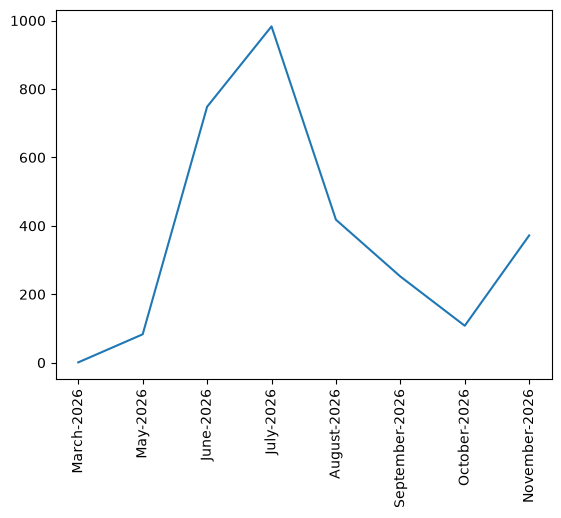

In [84]:
plt.plot(timeline["time"], timeline["message"])
plt.xticks(rotation='vertical')
plt.show()

In [ ]:
df["only_date"] = df["date"].dt.date
daily_timeline = df.groupby('only_date').count()['message'].reset_index()



In [87]:
daily_timeline

,only_date,message
0,2026-03-25,1
1,2026-05-26,8
2,2026-05-27,25
3,2026-05-28,9
4,2026-05-29,15
...,...,...
157,2026-11-16,35
158,2026-11-17,22
159,2026-11-18,2
160,2026-11-19,3


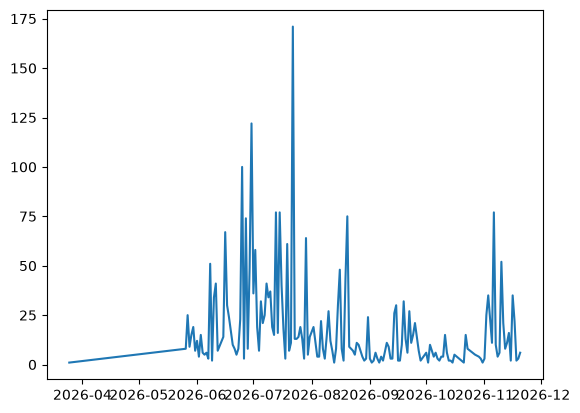

In [88]:
plt.plot(daily_timeline['only_date'], daily_timeline['message'])

In [ ]:
df["day_name"] = df["date"].dt.day_name()

In [90]:
df['day_name'].value_counts()

day_name
Wednesday    647
Thursday     508
Tuesday      479
Monday       427
Friday       338
Sunday       292
Saturday     274
Name: count, dtype: int64

In [91]:
df.head()

,date,user,message,year,month,day,hour,minute,month_num,only_date,day_name
0,2026-05-26 20:10:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026,May,26,20,10,5,2026-05-26,Tuesday
1,2026-03-25 15:34:00,group_notification,"Mummy created group ""👻👻F.R.I.E.N.D.S👻👻""\n",2026,March,25,15,34,3,2026-03-25,Wednesday
2,2026-05-26 20:10:00,group_notification,You joined using this group's invite link\n,2026,May,26,20,10,5,2026-05-26,Tuesday
3,2026-05-26 20:11:00,✌Divyam✌,Guys call cut karke phir se karo\n,2026,May,26,20,11,5,2026-05-26,Tuesday
4,2026-05-26 20:11:00,Amrita (Vasu),\n,2026,May,26,20,11,5,2026-05-26,Tuesday


In [92]:
period = []
for hour in df[["day_name", "hour"]]["hour"]:
    if hour == 23:
        period.append(str(hour) + "-" + str("00"))
    elif hour == 0:
        period.append(str("00") + "-" + str(hour + 1))
    else:
        period.append(str(hour) + "-" + str(hour + 1))

In [94]:
df["period"] = period

In [95]:
df.head()

,date,user,message,year,month,day,hour,minute,month_num,only_date,day_name,period
0,2026-05-26 20:10:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026,May,26,20,10,5,2026-05-26,Tuesday,20-21
1,2026-03-25 15:34:00,group_notification,"Mummy created group ""👻👻F.R.I.E.N.D.S👻👻""\n",2026,March,25,15,34,3,2026-03-25,Wednesday,15-16
2,2026-05-26 20:10:00,group_notification,You joined using this group's invite link\n,2026,May,26,20,10,5,2026-05-26,Tuesday,20-21
3,2026-05-26 20:11:00,✌Divyam✌,Guys call cut karke phir se karo\n,2026,May,26,20,11,5,2026-05-26,Tuesday,20-21
4,2026-05-26 20:11:00,Amrita (Vasu),\n,2026,May,26,20,11,5,2026-05-26,Tuesday,20-21


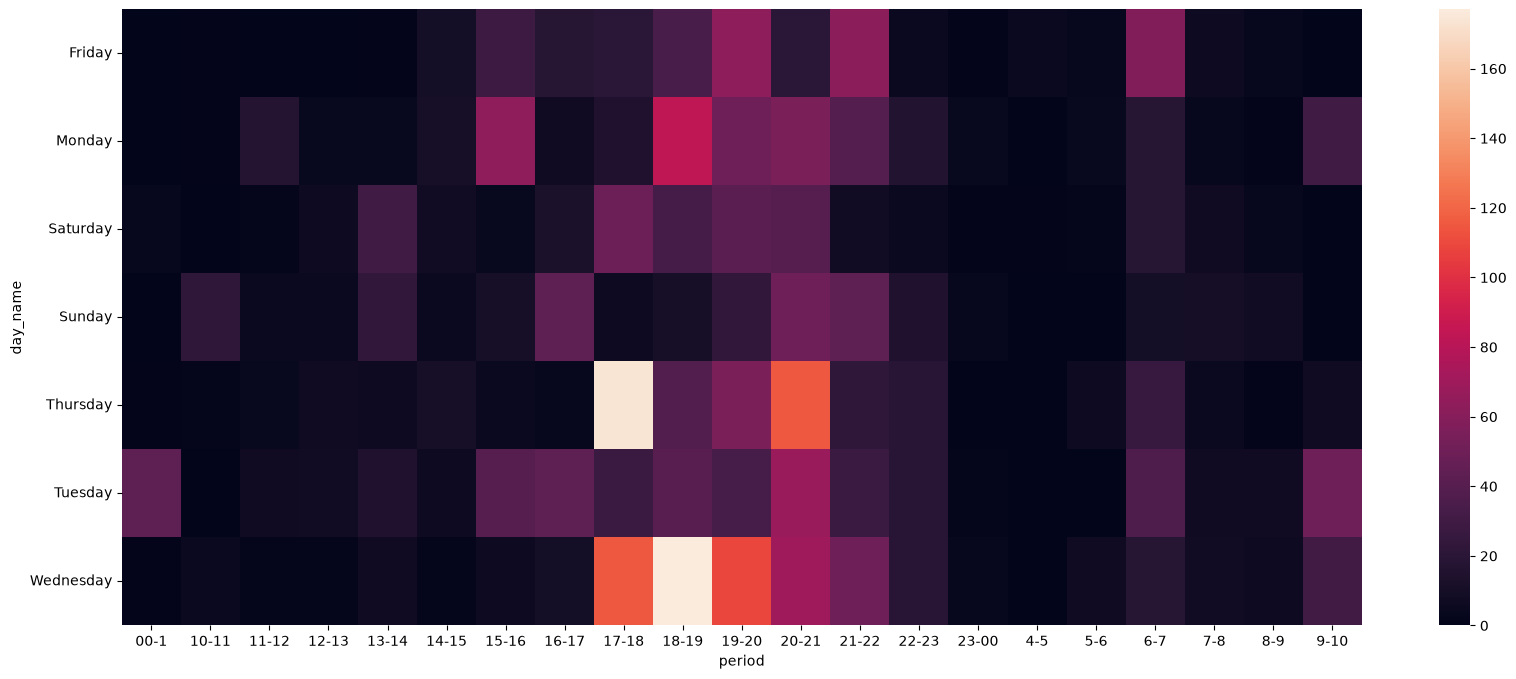

In [99]:
plt.figure(figsize=(20, 8))
sns.heatmap(
    df.pivot_table(
        index="day_name", columns="period", values="message", aggfunc="count"
    ).fillna(0)
)
plt.yticks(rotation="horizontal")
plt.show()

In [ ]:
words = []
for message in df['message']:
    words.extend(message.split())

In [ ]:
len(words)

In [ ]:
l = df['message'].head()

In [ ]:
l

In [ ]:
from urlextract import URLExtract

extractor = URLExtract()

y = []

for message in df["message"]:
    y.extend(extractor.find_urls(message))

In [ ]:
len(y)

In [ ]:
x = df["user"].value_counts().head()

In [ ]:
name = x.index
count = x.values

plt.bar(name, count)
plt.xticks(rotation="vertical")

In [ ]:
(
    (df["user"].value_counts() / df.shape[0] * 100)
    .reset_index()
    .rename(columns={"user": "name", "count": "percent"})
    .round({"percent": 2})
)

In [ ]:
from wordcloud import WordCloud

In [ ]:
temp = df[df["user"] != "group_notification"]
temp = temp[temp["message"] != "<Media omitted>\n"]

In [ ]:
f = open(r"D:\Divyam\Projects\whatsapp-chat-analysis\stop_hinglish.txt", "r")
stop_words = f.read()

In [ ]:
words = []

for message in temp["message"]:
    for word in message.lower().split():
        if word not in stop_words:
            words.append(word)



In [ ]:
from collections import Counter

df = pd.DataFrame(Counter(words).most_common(20)).rename(
    columns={0: "word", 1: "count"}
)

df

In [ ]:
import emoji
from collections import Counter

In [ ]:
emojis = []

for message in df["message"]:
    emojis.extend(emoji.distinct_emoji_list(message))

pd.DataFrame(Counter(emojis).most_common(len(Counter(emojis))))